In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
view_df = pd.read_csv("World-Bank-Data-by-Indicators/social-development/social-development.csv")
view_df.head(10)

,Country Name,Country Code,Year,"average_value_Adolescent fertility rate (births per 1,000 women ages 15-19)","average_value_Children in employment, female (% of female children ages 7-14)","average_value_Children in employment, male (% of male children ages 7-14)","average_value_Children in employment, study and work (% of children in employment, ages 7-14)","average_value_Children in employment, study and work, female (% of female children in employment, ages 7-14)","average_value_Children in employment, study and work, male (% of male children in employment, ages 7-14)","average_value_Children in employment, total (% of children ages 7-14)",...,average_value_Refugee population by country or territory of asylum,average_value_Refugee population by country or territory of origin,"average_value_School enrollment, primary (gross), gender parity index (GPI)","average_value_School enrollment, primary and secondary (gross), gender parity index (GPI)","average_value_School enrollment, secondary (gross), gender parity index (GPI)","average_value_School enrollment, tertiary (gross), gender parity index (GPI)","average_value_Unemployment, female (% of female labor force) (modeled ILO estimate)","average_value_Unemployment, male (% of male labor force) (modeled ILO estimate)","average_value_Vulnerable employment, female (% of female employment) (modeled ILO estimate)","average_value_Vulnerable employment, male (% of male employment) (modeled ILO estimate)"
0,Afghanistan,AFG,1990,162.835400,NaN,NaN,NaN,NaN,NaN,NaN,...,50.0,6339095.0,0.54850,NaN,NaN,0.47453,NaN,NaN,NaN,NaN
1,Afghanistan,AFG,1994,164.448600,NaN,NaN,NaN,NaN,NaN,NaN,...,19134.0,2731166.0,0.50580,0.43200,0.28143,NaN,14.76,11.09,98.600003,90.540001
2,Africa Western and Central,AFW,1969,172.026085,NaN,NaN,NaN,NaN,NaN,NaN,...,131200.0,71050.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Africa Western and Central,AFW,1989,156.266617,NaN,NaN,NaN,NaN,NaN,NaN,...,132129.0,199380.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Angola,AGO,1973,224.736000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,426550.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Antigua and Barbuda,ATG,1989,78.701200,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Belgium,BEL,2008,9.229800,NaN,NaN,NaN,NaN,NaN,NaN,...,17025.0,58.0,0.99767,1.08786,1.14633,1.20925,7.60,6.47,8.670000,11.100000
7,Belize,BLZ,2012,72.679000,NaN,NaN,NaN,NaN,NaN,NaN,...,27.0,35.0,0.96648,0.99023,1.03051,1.39512,12.72,5.80,25.760000,30.169999
8,Bermuda,BMU,1978,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.96578,1.02015,1.09112,NaN,NaN,NaN,NaN,NaN
9,Botswana,BWA,1972,156.218000,NaN,NaN,NaN,NaN,NaN,NaN,...,4500.0,NaN,1.16193,1.11871,0.83328,0.38415,NaN,NaN,NaN,NaN


In [3]:
view_df.columns

Index(['Country Name', 'Country Code', 'Year',
       'average_value_Adolescent fertility rate (births per 1,000 women ages 15-19)',
       'average_value_Children in employment, female (% of female children ages 7-14)',
       'average_value_Children in employment, male (% of male children ages 7-14)',
       'average_value_Children in employment, study and work (% of children in employment, ages 7-14)',
       'average_value_Children in employment, study and work, female (% of female children in employment, ages 7-14)',
       'average_value_Children in employment, study and work, male (% of male children in employment, ages 7-14)',
       'average_value_Children in employment, total (% of children ages 7-14)',
       'average_value_Children in employment, work only (% of children in employment, ages 7-14)',
       'average_value_Children in employment, work only, female (% of female children in employment, ages 7-14)',
       'average_value_Children in employment, work only, male (%

In [4]:
viet_df = view_df[view_df['Country Name'] == 'Vietnam']
phil_df = view_df[view_df['Country Name'] == 'Philippines']
thai_df = view_df[view_df['Country Name'] == 'Thailand']

X='Year'
Y_mean_v = viet_df['average_value_Unemployment, female (% of female labor force) (modeled ILO estimate)'].mean()
Y_mean_t = thai_df['average_value_Unemployment, female (% of female labor force) (modeled ILO estimate)'].mean()
Y = 'average_value_Unemployment, female (% of female labor force) (modeled ILO estimate)'

Y2 = viet_df['average_value_Unemployment, female (% of female labor force) (modeled ILO estimate)']
Y2_log = np.log1p(Y2)

viet_df['average_value_Unemployment, female (% of female labor force) (modeled ILO estimate) log'] = Y2_log

Y_mean_vLog = viet_df['average_value_Unemployment, female (% of female labor force) (modeled ILO estimate) log'].mean()


In [5]:
### Final Visualizations

Text(0, 0.5, 'Average Female Unemployment Rate (modeled ILO estimate)')

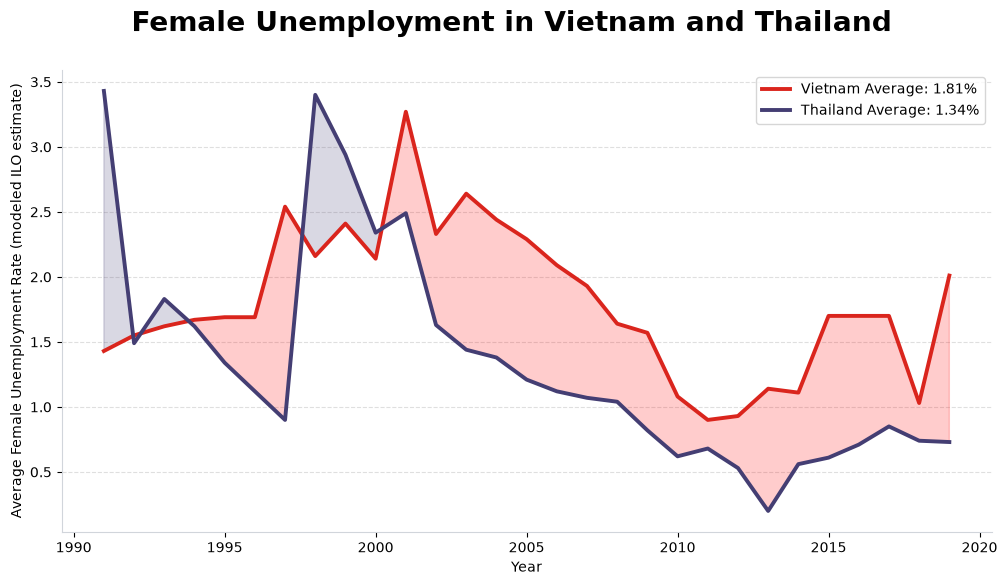

In [6]:
fig, axes = plt.subplots(1,1, figsize=(12,6))

sns.lineplot(data=viet_df, x=X, y=Y, color="#DA251D",
             label=f'Vietnam Average: {Y_mean_v:.2f}%', ax=axes, linewidth=2.8)
sns.lineplot(data=thai_df, x=X, y=Y, color="#443E73", 
             label=f'Thailand Average: {Y_mean_t:.2f}%', ax=axes, linewidth=2.8)

Y = 'average_value_Unemployment, female (% of female labor force) (modeled ILO estimate)'

# Align rates by year
rates = pd.concat(
    [
        viet_df.set_index('Year')[Y].rename('Vietnam'),
        thai_df.set_index('Year')[Y].rename('Thailand')
    ],
    axis=1,
    join='inner'
).dropna().sort_index()

years = rates.index.to_numpy(dtype=float)
vietnam = rates['Vietnam'].to_numpy(dtype=float)
thailand = rates['Thailand'].to_numpy(dtype=float)

# Vietnam higher: faded red
axes.fill_between(
    years, vietnam, thailand,
    where=vietnam > thailand,
    color='red', alpha=0.2,
    interpolate=True, zorder=1
)

# Vietnam lower: faded green
axes.fill_between(
    years, vietnam, thailand,
    where=vietnam < thailand,
    color="#443E73", alpha=0.2,
    interpolate=True, zorder=1
)

fig.suptitle(
    "Female Unemployment in Vietnam and Thailand",
    fontsize=20,
    fontweight="bold"
)

for side in ['top', 'right']:
    axes.spines[side].set_visible(False)

for side in ['left', 'bottom']:
    axes.spines[side].set_color('#D1D5DB')

axes.grid(True, axis='y', linestyle='--', alpha=0.4)
axes.set_axisbelow(True)  
plt.ylabel("Average Female Unemployment Rate (modeled ILO estimate)")

Text(0, 0.5, 'Average Female Unemployment Rate (modeled ILO estimate)')

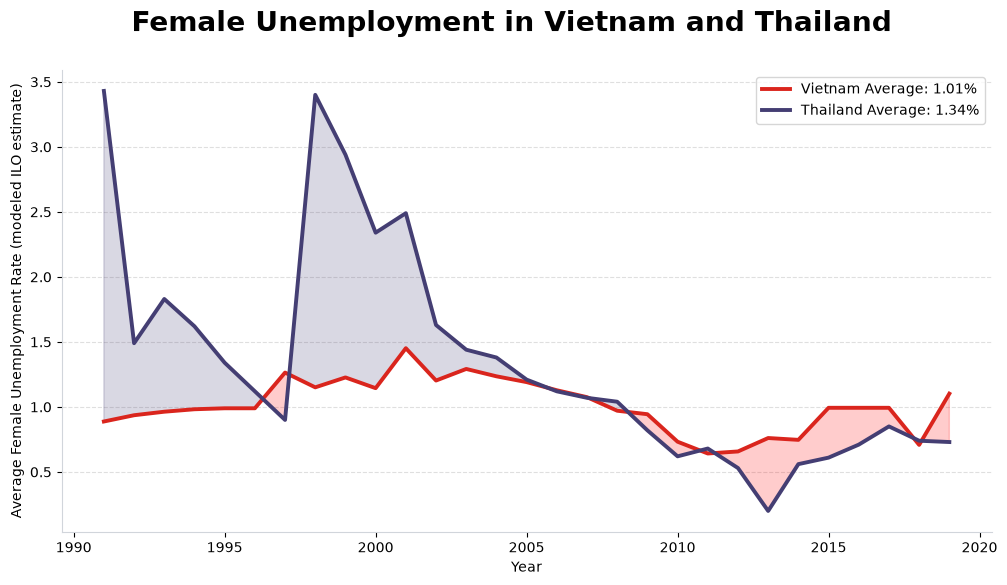

In [8]:
fig, axes = plt.subplots(1,1, figsize=(12,6))

sns.lineplot(data=viet_df, x=X, y='average_value_Unemployment, female (% of female labor force) (modeled ILO estimate) log', color="#DA251D",
             label=f'Vietnam Average: {Y_mean_vLog:.2f}%', ax=axes, linewidth=2.8)
sns.lineplot(data=thai_df, x=X, y=Y, color="#443E73", 
             label=f'Thailand Average: {Y_mean_t:.2f}%', ax=axes, linewidth=2.8)

Y = 'average_value_Unemployment, female (% of female labor force) (modeled ILO estimate)'

# Align rates by year
rates = pd.concat(
    [
        viet_df.set_index('Year')['average_value_Unemployment, female (% of female labor force) (modeled ILO estimate) log'].rename('Vietnam'),
        thai_df.set_index('Year')[Y].rename('Thailand')
    ],
    axis=1,
    join='inner'
).dropna().sort_index()

years = rates.index.to_numpy(dtype=float)
vietnam = rates['Vietnam'].to_numpy(dtype=float)
thailand = rates['Thailand'].to_numpy(dtype=float)

# Vietnam higher: faded red
axes.fill_between(
    years, vietnam, thailand,
    where=vietnam > thailand,
    color='red', alpha=0.2,
    interpolate=True, zorder=1
)

# Vietnam lower: faded green
axes.fill_between(
    years, vietnam, thailand,
    where=vietnam < thailand,
    color="#443E73", alpha=0.2,
    interpolate=True, zorder=1
)

fig.suptitle(
    "Female Unemployment in Vietnam and Thailand",
    fontsize=20,
    fontweight="bold"
)

for side in ['top', 'right']:
    axes.spines[side].set_visible(False)

for side in ['left', 'bottom']:
    axes.spines[side].set_color('#D1D5DB')

axes.grid(True, axis='y', linestyle='--', alpha=0.4)
axes.set_axisbelow(True)  
plt.ylabel("Average Female Unemployment Rate (modeled ILO estimate)")